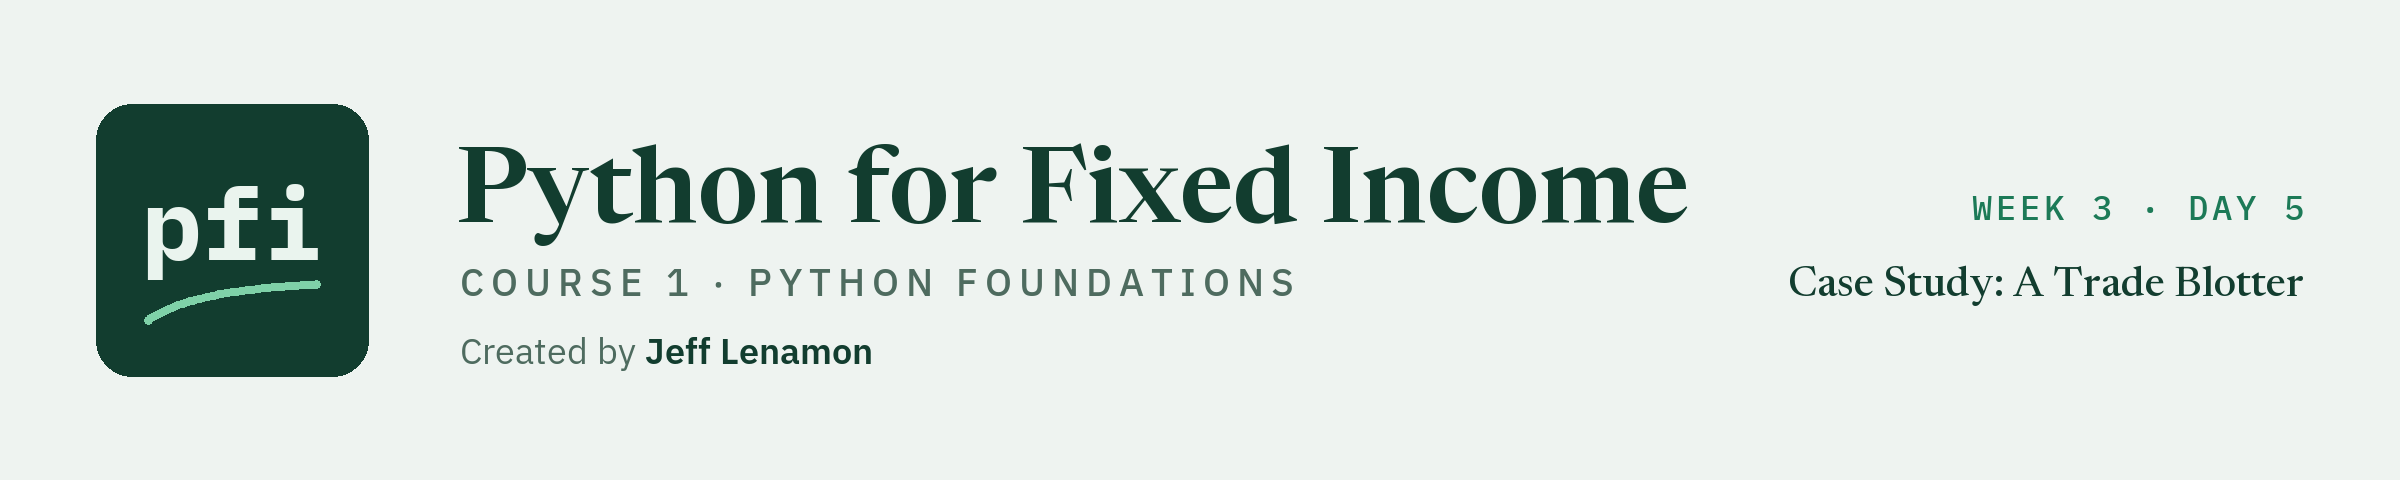

# Case Study: A Trade Blotter

Week 3, Day 5. One month of the desk's trades is checked, read a column at a time, joined to the holdings, and written up as one page.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day5/15_case_study_trade_blotter.ipynb)

## Problem Definition

### Context

The desk lead's twentieth note:

> Month-end meeting: I need one page on September from the blotter, with every total tied to the file. Describe it: no views on bonds, dealers, or desks.

The **trade blotter** is the desk's list of every trade it made.
Every name in the file is invented.

### Objective

You are the desk's analyst, with a file you have never seen.

Answer the six questions the page needs:

1. How much did the desk trade, and how big were the trades?
2. Was it a net buyer or seller, in total and by sector?
3. Who did it trade with?
4. How much of each sector's holding changed hands?
5. When did it trade?
6. How did the net build through the month?

### The Data

`trade_blotter.csv` in `data`: one row per trade, 2026-09-01 to 2026-09-30, each in a bond of `holdings.csv`.

<table align="left">
<tr><th align="left">Column</th><th align="left">Holds</th></tr>
<tr><td align="left"><code>trade_id</code>, <code>trader</code></td><td align="left">the trade; the desk, Desk 1 to Desk 4</td></tr>
<tr><td align="left"><code>trade_date</code>, <code>trade_time</code>, <code>settle_date</code></td><td align="left">when it was traded and when it settles</td></tr>
<tr><td align="left"><code>cusip</code>, <code>ticker</code>, <code>counterparty</code></td><td align="left">the bond; the dealer on the other side</td></tr>
<tr><td align="left"><code>side</code>, <code>quantity</code>, <code>price</code></td><td align="left"><code>BUY</code> or <code>SELL</code>; face; clean price</td></tr>
<tr><td align="left"><code>principal</code></td><td align="left">quantity x price / 100, without accrued interest</td></tr>
</table>
<br clear="left">

**Face and principal in dollars, prices per 100 of face, totals in millions.**

### How We Will Work

![The day as a route in two rows: blotter.csv, 374 trades; 15.1 load and check, lit, seven checks and the month drawn; 15.2 one column, size, hour, weekday; 15.3 join the book, a sector and a grade per trade; 15.4 two columns, side by sector, dealer, grade; 15.5 against the book, turnover and one bond; 15.6 through the month, by desk then a running net; the page, six answers, every total ties to the file](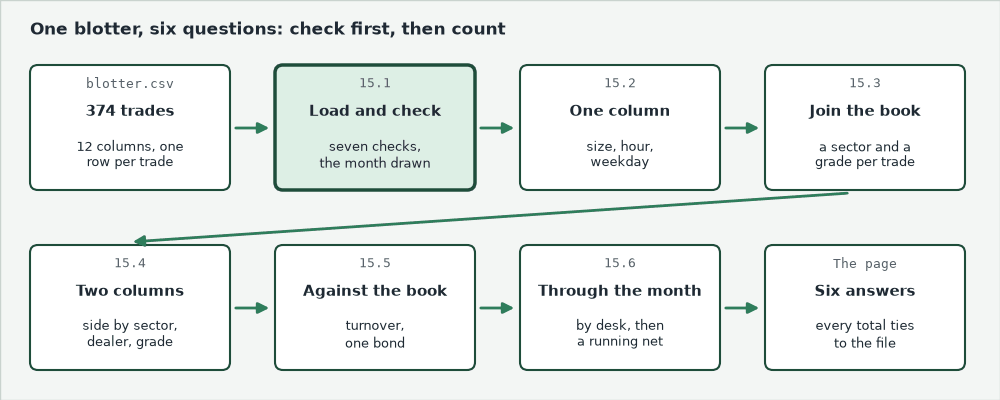)

The EDA notebook's order holds on a new file.

**Check the file before any total.**

## 15.1 Loading and Checking the Blotter

### The File

Q. Read the blotter with its two date columns as dates. What is one row?

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house theme, as in Visualization: greens and greys, a dark median in a box
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/trade_blotter.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# parse_dates= reads the two date columns as dates, as in Combining Part 2
blotter = pd.read_csv(data_folder + 'trade_blotter.csv', parse_dates=['trade_date', 'settle_date'])
print(blotter.shape)
blotter.head(2)

(374, 12)


,trade_id,trade_date,trade_time,settle_date,cusip,ticker,side,quantity,price,principal,counterparty,trader
0,T0001,2026-09-01,08:04,2026-09-02,99087JAG1,KRIX,BUY,500000,103.053,515265.0,Ulverthorne Markets,Desk 4
1,T0002,2026-09-01,09:10,2026-09-02,99003DAE0,PLWK,SELL,245000,95.434,233813.3,Talvesham Partners,Desk 2


`T0001` bought 500,000 of face at 103.053: 500,000 x 103.053 / 100 is its 515,265 of principal.

Q. Which columns came in as dates?

In [2]:
blotter.dtypes

trade_id                   str
trade_date      datetime64[us]
trade_time                 str
settle_date     datetime64[us]
cusip                      str
ticker                     str
side                       str
quantity                 int64
price                  float64
principal              float64
counterparty               str
trader                     str
dtype: object

`trade_date` and `settle_date` are `datetime64`; `trade_time` is `str`, text, not a time.

### Four Checks on the File Itself

Q. Is every id there once, any cell blank, any row repeated, and `side` only `BUY` or `SELL`?

In [3]:
# is_unique, isna() and duplicated(), as in A First Look at the Data
ids_unique = blotter['trade_id'].is_unique
blanks = blotter.isna().sum().sum()
repeats = blotter.duplicated().sum()
print('ids unique:', ids_unique, '| blank cells:', blanks, '| repeated rows:', repeats)
print(blotter['side'].value_counts().to_dict())
# assert with a message, as on week 1's Day 3: next month's run stops here if a check fails
assert ids_unique and blanks == 0 and repeats == 0, 'a repeated id, a blank, or a repeated row'
assert blotter['side'].isin(['BUY', 'SELL']).all(), 'side holds something other than BUY or SELL'

ids unique: True | blank cells: 0 | repeated rows: 0
{'BUY': 197, 'SELL': 177}


Every id once, no blank, no repeat, and no stray `Buy`: 197 buys and 177 sells.
Print for the reader, assert for the run nobody watches.

### Three Tie-Outs

Q. Does every principal equal quantity x price / 100, is every quantity a round lot of 5,000, and is every bond held?

In [4]:
largest_gap = (blotter['quantity'] * blotter['price'] / 100 - blotter['principal']).abs().max()
# % is the remainder, as in Day 0: a multiple of 5,000 leaves 0
odd_lots = (blotter['quantity'] % 5000 != 0).sum()
holdings = pd.read_csv(data_folder + 'holdings.csv')
in_book = blotter['cusip'].isin(holdings['cusip'])
print('largest gap, dollars:', round(largest_gap, 2), '| odd lots:', odd_lots,
      '| in the book:', in_book.sum())
# nunique(): how many different values, as in pandas Part 2
print('bonds traded:', blotter['cusip'].nunique(), 'of', len(holdings),
      '| trade dates:', blotter['trade_date'].nunique())
# half a cent of room: two routes to a decimal can differ in the last digit, as on week 1's Day 3
assert largest_gap < 0.005 and odd_lots == 0 and in_book.all(), 'a tie-out failed'

largest gap, dollars: 0.0 | odd lots: 0 | in the book: 374
bonds traded: 128 of 200 | trade dates: 21


Every principal ties to the cent, every quantity is a round lot, and every trade is in a bond the book holds: 128 of the 200 traded, on 21 dates.

**Excel side by side.** The blotter in A to L, rows 2 to 375; `holdings` on a second sheet.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Blank cells</td><td align="left"><code>isna().sum().sum()</code></td><td align="left"><code>=COUNTBLANK(A2:L375)</code></td><td align="left">0</td></tr>
<tr><td align="left">Round lots</td><td align="left"><code>quantity % 5000</code></td><td align="left"><code>=MOD(H2,5000)</code> filled down</td><td align="left">0 on every row</td></tr>
<tr><td align="left">In the book</td><td align="left"><code>isin()</code></td><td align="left"><code>=COUNTIF(holdings!B:B,E2)</code> filled down</td><td align="left">1 on every row</td></tr>
<tr><td align="left">Stop on a failure</td><td align="left"><code>assert</code></td><td align="left">a check cell, <code>=IF(COUNTBLANK(A2:L375)=0,"ok","STOP")</code></td><td align="left"><code>ok</code>, but it stops nothing</td></tr>
</table>
<br clear="left">

**A clean result is a result: seven checks, all passed, all written down.**

### Predict 1: Trade Date to Settle Date

**Predict 1**

Q. Each trade settles one business day after its trade date. How many different values does `(blotter['settle_date'] - blotter['trade_date']).dt.days` hold?

A) one: 1
B) two: 1, and 3 for a Friday
C) three

In [5]:
# date minus date, then .dt.days, as in Combining Part 2
gap_days = (blotter['settle_date'] - blotter['trade_date']).dt.days
print(gap_days.value_counts().to_dict())
# September's weekdays and the one with no trade, as in the Treasury case study
weekdays = pd.date_range('2026-09-01', '2026-09-30', freq='B')
no_trade = weekdays.difference(blotter['trade_date'])
print('weekdays:', len(weekdays), '| no trade on:', no_trade[0].date())
# the dates behind the longest gap; drop_duplicates() as in the EDA notebook
blotter.loc[gap_days == 4, ['trade_date', 'settle_date']].drop_duplicates()

{1: 319, 3: 41, 4: 14}
weekdays: 22 | no trade on: 2026-09-07


,trade_date,settle_date
54,2026-09-04,2026-09-08


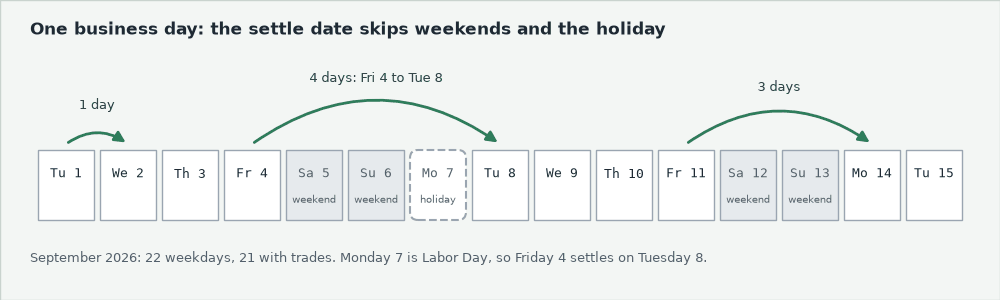

C: 319 trades settle a day later, 41 Friday trades three days later, and 14 four days later, from Friday 2026-09-04 to Tuesday 2026-09-08.
September has 22 weekdays and the file 21 trade dates: Monday 2026-09-07 is not a business day here.

**One business day is not one day.**

> STORY: Since 2024-05-28, most US broker-dealer trades settle one business day after the trade date, under the SEC's move from T+2 to T+1 ([SEC press release 2023-29](https://www.sec.gov/newsroom/press-releases/2023-29)). Labor Day is "the first Monday in September" under federal law ([5 U.S.C. 6103](https://www.law.cornell.edu/uscode/text/5/6103)); in 2026, 2026-09-07, the weekday the file skips.

**Excel side by side.** With the holiday in T1, `=D2=WORKDAY(B2,1,$T$1)` filled down is TRUE on every row; leave out `$T$1` and the 14 rows traded on 2026-09-04 turn FALSE.

### The Month at a Glance

Q. How many trades, and how many dollars, day by day?

In [6]:
# size() counts the rows of each group, as in the Treasury case study
trades_by_day = blotter.groupby('trade_date').size()
print('trades:', trades_by_day.sum(),
      '| principal, millions:', round(blotter['principal'].sum() / 1_000_000, 2))
print('mean a day:', round(trades_by_day.mean(), 1),
      '| busiest:', trades_by_day.idxmax().date(), trades_by_day.max(),
      '| quietest:', trades_by_day.idxmin().date(), trades_by_day.min())

trades: 374 | principal, millions: 117.47
mean a day: 17.8 | busiest: 2026-09-29 29 | quietest: 2026-09-28 7


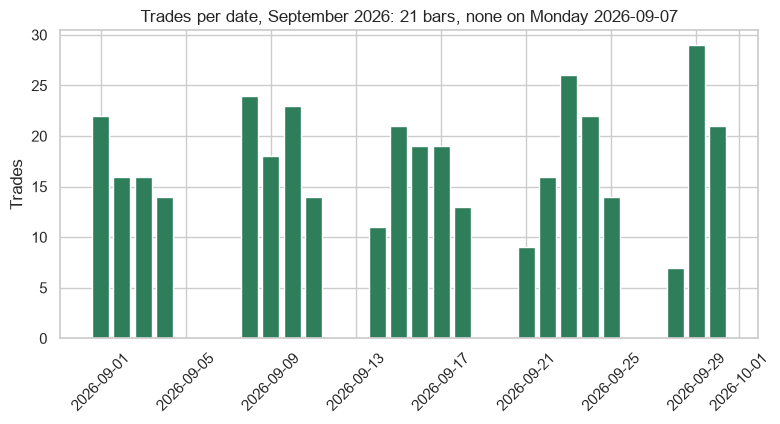

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(trades_by_day.index, trades_by_day.values)
ax.set_title('Trades per date, September 2026: 21 bars, none on Monday 2026-09-07')
ax.set_ylabel('Trades')
ax.tick_params(axis='x', rotation=45)
plt.show()

The busiest date, 2026-09-29 with 29, follows the quietest, 2026-09-28 with 7.
The wider gap after 2026-09-04 is the holiday weekend: Saturday, Sunday, and Labor Day.

**374 trades, 117.47 million dollars, 21 dates. Now one column at a time.**

## 15.2 One Column at a Time

### How Big Is a Trade

Q. Describe `quantity`, the face of each trade.

In [8]:
blotter['quantity'].describe().round()

count        374.0
mean      312968.0
std       444799.0
min        10000.0
25%       100000.0
50%       200000.0
75%       400000.0
max      5000000.0
Name: quantity, dtype: float64

Median 200,000, mean 312,968: skewed right, as in Visualization.
The middle half runs 100,000 to 400,000, and the largest is 5,000,000.

Q. Draw the sizes in bins 100 thousand wide.

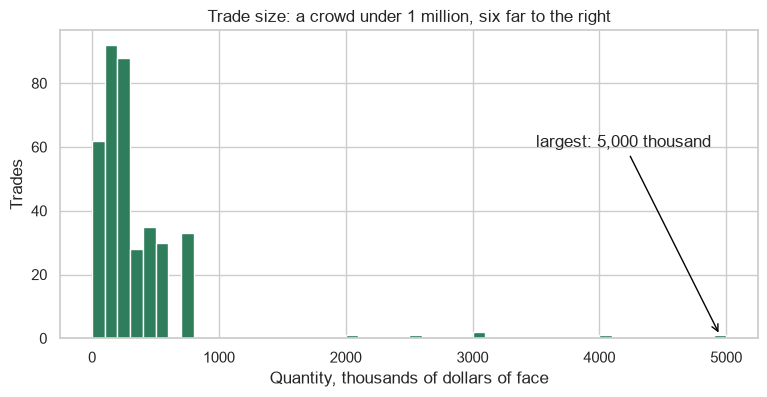

1,000,000 or less: 368


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
# thousands of dollars, in bins 100 thousand wide
ax.hist(blotter['quantity'] / 1000, bins=range(0, 5100, 100))
ax.annotate('largest: 5,000 thousand', xy=(4950, 1), xytext=(3500, 60),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('Trade size: a crowd under 1 million, six far to the right')
ax.set_xlabel('Quantity, thousands of dollars of face')
ax.set_ylabel('Trades')
plt.show()
print('1,000,000 or less:', (blotter['quantity'] <= 1_000_000).sum())

368 trades fill the left fifth of the chart; six stand alone.

### Six Trades Far From the Rest

Q. Which trades does the IQR rule flag, as in the EDA notebook?

In [10]:
q1, q3 = blotter['quantity'].quantile(0.25), blotter['quantity'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
flagged = blotter[blotter['quantity'] > upper_limit]
share = flagged['principal'].sum() / blotter['principal'].sum() * 100
print('limit:', upper_limit, '| flagged:', len(flagged))
print('principal, millions:', round(flagged['principal'].sum() / 1_000_000, 2),
      '|', round(share, 1), 'percent of the dollars')
flagged[['trade_id', 'trade_date', 'ticker', 'side', 'quantity', 'price']]

limit: 850000.0 | flagged: 6
principal, millions: 19.41 | 16.5 percent of the dollars


,trade_id,trade_date,ticker,side,quantity,price
50,T0051,2026-09-03,RULL,SELL,4000000,103.059
137,T0138,2026-09-11,THAN,SELL,2000000,94.181
150,T0151,2026-09-14,DRAH,BUY,2500000,94.101
159,T0160,2026-09-15,CLAE,SELL,5000000,106.702
236,T0237,2026-09-21,PLER,BUY,3000000,98.307
366,T0367,2026-09-30,VRAN,SELL,3000000,92.203


Past the 850,000 limit, six trades of 2 to 5 million carry 16.5 percent of the dollars.
Far is not wrong, as the EDA notebook showed: test a second column.

Q. How far is each flagged price from its bond's month-end price in the holdings?

In [11]:
# the holdings' price is the month-end price: rename it to keep the two apart
month_end_prices = holdings[['cusip', 'price']].rename(columns={'price': 'month_end_price'})
gaps = pd.merge(flagged, month_end_prices, on='cusip')
print('largest gap, points:', round((gaps['price'] - gaps['month_end_price']).abs().max(), 3))

largest gap, points: 0.719


Each flagged price is within 0.719 points of its month end, and each principal tied: six real trades, kept.
The largest, `T0160`, sold 5,000,000 of CLAE on 2026-09-15; it returns at the end.

**An outlier is not an error: six real trades, a sixth of the dollars.**

### The Hour of a Trade

Q. Take the hour of each trade from `trade_time`.

In [12]:
# .dt reaches the parts of a date or a time
blotter['trade_time'].dt.hour

AttributeError: Can only use .dt accessor with datetimelike values

Read the last line, as on week 1's Day 3: `.dt` needs dates or times, and `trade_time` is text.

Q. Read the text as a time, then take the hour.

In [13]:
# format= gives the text's layout, as in Combining Part 2
# %H is the hour on a 24-hour clock, %M the minute
as_time = pd.to_datetime(blotter['trade_time'], format='%H:%M')
# .dt.hour: the hour of each time, 8 for 08:04
blotter['hour'] = as_time.dt.hour
print(as_time.iloc[0], '| hour:', blotter['hour'].iloc[0])
print('first:', blotter['trade_time'].min(), '| last:', blotter['trade_time'].max())

1900-01-01 08:04:00 | hour: 8
first: 08:04 | last: 16:59


With no date in the text, pandas filled in 1900-01-01; only the hour is kept.
Trading ran from 08:04 to 16:59.

### Trades by Hour

Q. How many trades were made in each hour?

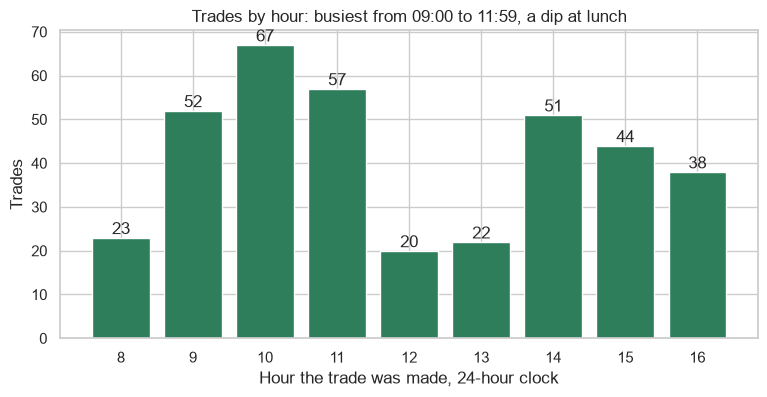

In [14]:
trades_by_hour = blotter['hour'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(trades_by_hour.index, trades_by_hour.values)
ax.bar_label(bars)
ax.set_xticks(trades_by_hour.index)
ax.set_title('Trades by hour: busiest from 09:00 to 11:59, a dip at lunch')
ax.set_xlabel('Hour the trade was made, 24-hour clock')
ax.set_ylabel('Trades')
plt.show()

10:00 is busiest with 67, between 09:00 with 52 and 11:00 with 57.
Lunch is quiet, and 14:00 climbs back to 51.

### The Week in Order

Q. Name each trade's weekday, in the order of the week, not the alphabet.

In [15]:
week = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
# day_name(), as in Combining Part 2
# pd.Categorical(ordered=True): text with a fixed order, which groupby and charts follow
blotter['weekday'] = pd.Categorical(blotter['trade_date'].dt.day_name(),
                                    categories=week, ordered=True)
blotter['weekday'].head(2)

0    Tuesday
1    Tuesday
Name: weekday, dtype: category
Categories (5, str): ['Monday' < 'Tuesday' < 'Wednesday' < 'Thursday' < 'Friday']

### Predict 2: Per Trading Day

**Predict 2**

Q. Wednesdays had 100 trades in September, Thursdays 80. Which had more trades per trading day?

A) Wednesday
B) Thursday
C) the same

In [16]:
# count: trades; nunique: different dates. observed=True as in Combining Part 2
by_weekday = blotter.groupby('weekday', observed=True)['trade_date'].agg(['count', 'nunique'])
by_weekday['per_day'] = by_weekday['count'] / by_weekday['nunique']
by_weekday

,count,nunique,per_day
weekday,,,
Monday,27,3,9.00
Tuesday,112,5,22.40
Wednesday,100,5,20.00
Thursday,80,4,20.00
Friday,55,4,13.75


C: each had 20.00 trades a day, 100 on five Wednesdays and 80 on four Thursdays.
Tuesday leads at 22.40; Monday, with three dates, has 9.00.
A count by weekday mixes how busy a day is with how often it came round.

### Weekday by Hour

Q. Count the trades for every weekday and hour.

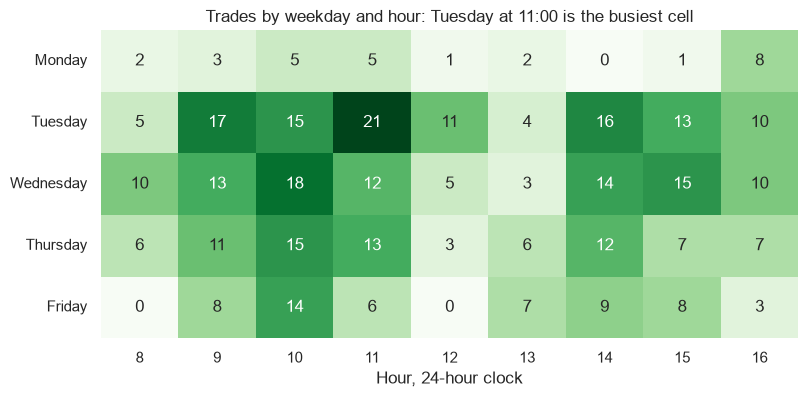

In [17]:
# crosstab() counts the rows for each pair of values: weekday down the side, hour across
by_weekday_hour = pd.crosstab(blotter['weekday'], blotter['hour'])
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(by_weekday_hour, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax)
ax.set_title('Trades by weekday and hour: Tuesday at 11:00 is the busiest cell')
ax.set_xlabel('Hour, 24-hour clock')
ax.set_ylabel('')
plt.show()

Tuesday at 11:00 holds 21; Friday has none at 08:00 or 12:00.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The hour</td><td align="left"><code>.dt.hour</code></td><td align="left"><code>=HOUR(C2)</code>: Microsoft 365 opens <code>08:04</code> as a time, not text</td><td align="left">8</td></tr>
<tr><td align="left">The weekday</td><td align="left"><code>.dt.day_name()</code></td><td align="left"><code>=TEXT(B2,"dddd")</code></td><td align="left">Tuesday</td></tr>
<tr><td align="left">Weekday by hour</td><td align="left"><code>pd.crosstab()</code></td><td align="left">a PivotTable: weekday in Rows, hour in Columns, Count of trade_id in Values</td><td align="left">the same counts</td></tr>
<tr><td align="left">Size histogram</td><td align="left"><code>ax.hist()</code></td><td align="left">Insert, Statistic Chart, Histogram (Excel 2016 and later)</td><td align="left">the same shape</td></tr>
</table>
<br clear="left">

**Mornings are busiest. The note's other questions need a sector, and the blotter has none.**

## 15.3 Joining the Blotter to the Holdings

### A Sector and a Grade for Every Trade

Q. Add each bond's issuer, sector, rating, month-end price, and market value, then the rating's grade. Is a trade still one row?

In [18]:
bond_details = holdings[['cusip', 'issuer', 'sector', 'rating', 'price', 'market_value']]
bond_details = bond_details.rename(columns={'price': 'month_end_price'})
# many trades to one bond, then many to one rating: validate= as in Combining Part 1
trades = pd.merge(blotter, bond_details, on='cusip', how='left', validate='many_to_one')
ratings = pd.read_csv(data_folder + 'ratings.csv')
trades = pd.merge(trades, ratings[['rating', 'grade']], on='rating', how='left',
                  validate='many_to_one')
print(len(blotter), 'in |', len(trades), 'out |', trades.shape[1], 'columns')
print('blank sector or grade:', trades[['sector', 'grade']].isna().sum().sum())
assert len(trades) == len(blotter), 'the join added or lost a trade'

374 in | 374 out | 20 columns
blank sector or grade: 0


The count held: `cusip` is unique in the holdings, and every trade found its bond in 15.1.

### Predict 3: The Other Way Round

**Predict 3**

Q. `pd.merge(holdings, blotter, on='cusip', how='left')` puts the 200 bonds on the left. How many rows come back? Write down a number.

In [19]:
other_way = pd.merge(holdings, blotter, on='cusip', how='left')
print(len(other_way), 'rows |', other_way['trade_id'].isna().sum(), 'with no trade')

446 rows | 72 with no trade


446 rows come back: one per trade for the 128 traded bonds, 374, and one each for the 72 untraded, since a left join keeps every left row (Combining Part 1).
Which table is on the left decides what one row is.

**374 in, 374 out: one row is still one trade.**

## 15.4 Two Columns at a Time

### Predict 4: More Buys, More Dollars?

**Predict 4**

Q. The desk made 197 buys and 177 sells. Do the counts say whether it was a net buyer or a net seller in dollars?

A) Yes: a net buyer, with 20 more buys
B) Yes: a net seller
C) No

In [20]:
by_side = trades.groupby('side')['principal'].agg(['count', 'sum'])
bought, sold = by_side.loc['BUY', 'sum'], by_side.loc['SELL', 'sum']
# net is signed, buys less sells; total is not, buys plus sells
print('bought:', round(bought / 1_000_000, 2), '| sold:', round(sold / 1_000_000, 2), 'million')
print('net:', round((bought - sold) / 1_000_000, 2),
      '| total:', round((bought + sold) / 1_000_000, 2), 'million')

bought: 56.56 | sold: 60.92 million
net: -4.36 | total: 117.47 million


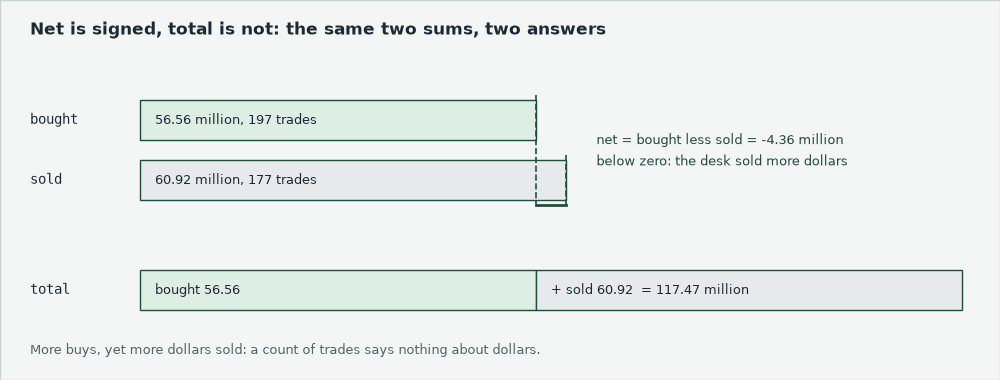

C: the desk made more buys, yet sold more dollars.
**Net**, buys less sells, is -4.36 million: below zero, the desk sold more.
**Total**, buys plus sells, is 117.47 million and never negative.

### Net by Sector

Q. Bought, sold, net, and total by sector, in millions?

In [21]:
by_sector = pd.pivot_table(trades, values='principal', index='sector', columns='side',
                           aggfunc='sum') / 1_000_000
by_sector['net'] = by_sector['BUY'] - by_sector['SELL']
by_sector['total'] = by_sector['BUY'] + by_sector['SELL']
# smallest net first, so the largest sits at the top of a horizontal bar chart
by_sector = by_sector.sort_values('net')
print('the nets add to:', round(by_sector['net'].sum(), 2))
by_sector.round(2)

the nets add to: -4.36


side,BUY,SELL,net,total
sector,,,,
Financials,4.54,11.59,-7.04,16.13
Consumer,7.04,13.09,-6.05,20.13
Technology,2.65,6.01,-3.35,8.66
Telecom,4.26,7.00,-2.74,11.26
Materials,6.27,5.92,0.35,12.18
Transportation,3.92,3.33,0.59,7.24
Health Care,6.08,4.02,2.06,10.10
Utilities,5.21,3.12,2.09,8.32
Industrials,7.30,3.88,3.41,11.18


The ten nets add to the blotter's -4.36.
Consumer traded the most, 20.13 million, for a net of -6.05; Materials' net of 0.35 hides 12.18 traded.

Q. Draw the nets, with zero marked.

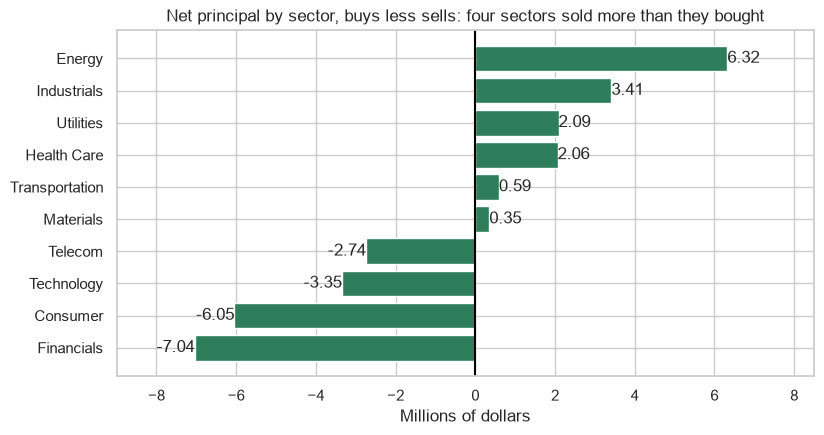

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(by_sector.index, by_sector['net'])
ax.bar_label(bars, fmt='%.2f')
# the zero line: bars to its left are net selling
ax.axvline(0, color='black')
# room for the labels, as in More Visualization
ax.set_xlim(-9, 8.5)
ax.set_title('Net principal by sector, buys less sells: four sectors sold more than they bought')
ax.set_xlabel('Millions of dollars')
plt.show()

Financials sold the most net, -7.04; Energy bought the most, 6.32.

### Counterparties by Count and by Dollars

Q. For each counterparty: how many trades, how many dollars, and the median trade size?

In [23]:
# named aggregation, as in Combining Part 1
by_dealer = trades.groupby('counterparty').agg(trade_count=('trade_id', 'count'),
                                              principal=('principal', 'sum'),
                                              median_size=('quantity', 'median'))
# principal in millions; the median size stays in dollars of face
by_dealer['principal'] = by_dealer['principal'] / 1_000_000
by_dealer = by_dealer.sort_values('trade_count', ascending=False)
by_dealer.round(2)

,trade_count,principal,median_size
counterparty,,,
Kestermoor Securities,86,15.95,150000.0
Zembrook Securities,66,18.58,200000.0
Orlinthe Capital,63,17.62,200000.0
Talvesham Partners,58,36.33,357500.0
Wendlecroft Securities,47,12.18,250000.0
Pendraleth Capital,27,8.61,250000.0
Ulverthorne Markets,27,8.20,200000.0


Kestermoor Securities leads by count, 86 trades for 15.95 million; Talvesham Partners by dollars, 36.33 million in 58.

### Why the Rankings Differ

Q. Draw each counterparty's trade sizes, most trades first.

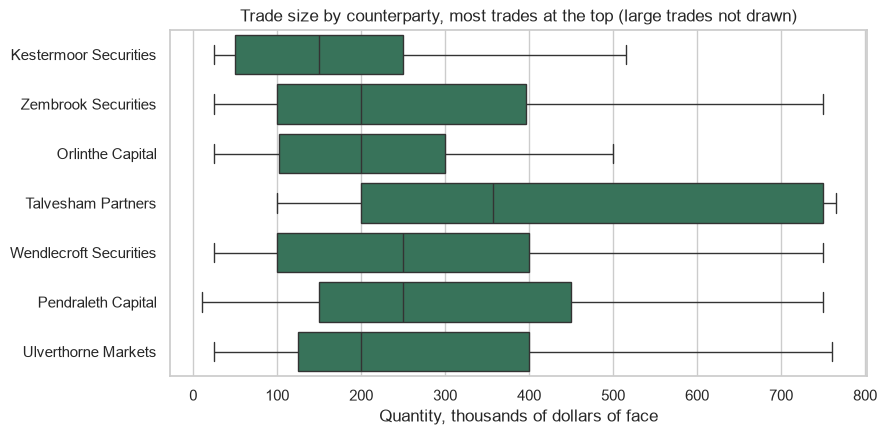

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
# sns.boxplot: one box per counterparty, in the order= given
# showfliers=False, as in the EDA notebook
sns.boxplot(x=trades['quantity'] / 1000, y=trades['counterparty'], order=by_dealer.index,
            showfliers=False, ax=ax)
ax.set_title('Trade size by counterparty, most trades at the top (large trades not drawn)')
ax.set_xlabel('Quantity, thousands of dollars of face')
ax.set_ylabel('')
plt.show()

Kestermoor's median line sits at 150 thousand, Talvesham's at 357.5: fewer, larger trades carry more dollars.

### Trade Size by Grade

Q. Are Investment Grade trades larger than High Yield trades?

In [25]:
trades.groupby('grade')['quantity'].agg(['count', 'median', 'mean', 'max']).round(0)

,count,median,mean,max
grade,,,,
High Yield,140,150000.0,174429.0,760000
Investment Grade,234,250000.0,395855.0,5000000


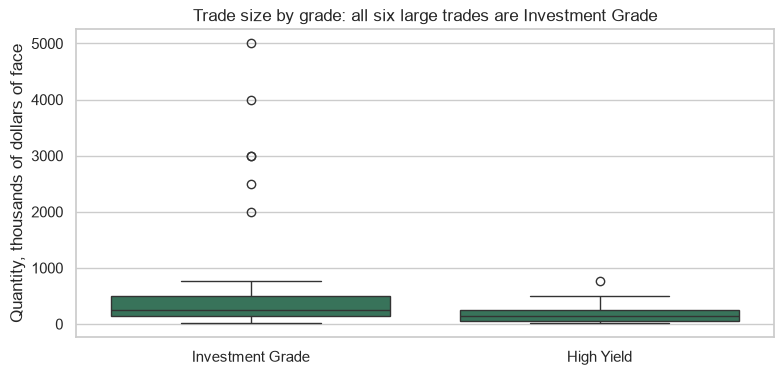

In [26]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x=trades['grade'], y=trades['quantity'] / 1000, ax=ax)
ax.set_title('Trade size by grade: all six large trades are Investment Grade')
ax.set_xlabel('')
ax.set_ylabel('Quantity, thousands of dollars of face')
plt.show()

The median Investment Grade trade is 250 thousand, High Yield's 150.
High Yield's largest, 760 thousand, is a circle in its own box yet under the blotter's 850,000 limit: far depends on the group.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Sector of a trade</td><td align="left"><code>pd.merge(how='left')</code></td><td align="left"><code>=XLOOKUP(E2,holdings!B:B,holdings!E:E)</code> in O, Excel 2021 and Microsoft 365 (<code>INDEX</code> and <code>MATCH</code> before)</td><td align="left">the first match, silently</td></tr>
<tr><td align="left">Net by sector</td><td align="left"><code>pivot_table()</code>, BUY less SELL</td><td align="left"><code>=SUMIFS(J:J,O:O,"Financials",G:G,"BUY")</code> less the same with <code>"SELL"</code></td><td align="left">-7,042,969.65</td></tr>
<tr><td align="left">By counterparty</td><td align="left">named aggregation</td><td align="left">a PivotTable with Count and Sum; it has no Median, so <code>=MEDIAN(IF(K2:K375="Kestermoor Securities",H2:H375))</code> (Ctrl+Shift+Enter before Excel 2021)</td><td align="left">150,000</td></tr>
<tr><td align="left">Size by group</td><td align="left"><code>sns.boxplot()</code></td><td align="left">Insert, Statistic Chart, Box and Whisker (Excel 2016 and later)</td><td align="left">the same boxes</td></tr>
</table>
<br clear="left">

**Say whether a figure is a count or dollars, a net or a total.**

## 15.5 The Blotter Against the Book

### Turnover

**Turnover** here is principal traded in the month, buys plus sells, as a percent of market value held at month end.
Funds publish a different rate: the smaller of a year's purchases and sales over the monthly average value of the securities held ([SEC Form N-1A](https://www.sec.gov/about/forms/formn-1a.pdf), Item 13, Instruction 4(d)), so the two do not compare.

### Predict 5: Market Value in the Joined Table

**Predict 5**

Q. `trades` carries each bond's `market_value`, and the book holds 490.82 million. What does `trades['market_value'].sum()` give?

A) 490.82 million
B) less: only 128 of the 200 bonds traded
C) more

In [27]:
print('trades:', round(trades['market_value'].sum() / 1_000_000, 2), 'million')
print('holdings:', round(holdings['market_value'].sum() / 1_000_000, 2), 'million')

trades: 1022.78 million
holdings: 490.82 million


![Left, holdings, one row per bond: CORA's market value, 2,310,390, counted once, and BEZE, which did not trade, counted once. Right, trades, one row per trade: the same 2,310,390 on each of CORA's 20 rows, which sum to 46,207,800; the whole column sums to 1,022.78 million against 490.82 held](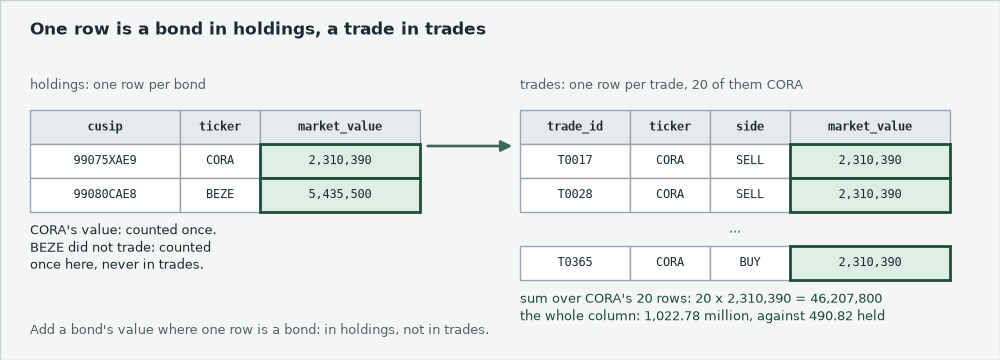)

C: the sum is 1,022.78 million, twice the book, and no error warns of it.
A bond traded 20 times carries its value on 20 rows of `trades`; an untraded bond, on none.

**A bond's value is added up where one row is a bond.**

### Turnover by Sector

Q. Principal traded over market value held, by sector?

In [28]:
# traded from trades, where one row is a trade; held from holdings, where one row is a bond
traded = trades.groupby('sector')['principal'].sum() / 1_000_000
held = holdings.groupby('sector')['market_value'].sum() / 1_000_000
# pandas lines the two up by sector name, as in pandas Part 1
turnover = pd.DataFrame({'traded': traded, 'held': held})
turnover['turnover_pct'] = turnover['traded'] / turnover['held'] * 100
whole_pct = traded.sum() / held.sum() * 100
print('whole book:', round(whole_pct, 1), 'percent')
turnover.sort_values('turnover_pct', ascending=False).round(2)

whole book: 23.9 percent


,traded,held,turnover_pct
sector,,,
Consumer,20.13,56.63,35.55
Energy,12.26,38.83,31.56
Utilities,8.32,29.01,28.70
Technology,8.66,30.31,28.56
Health Care,10.10,38.91,25.96
Financials,16.13,68.22,23.65
Industrials,11.18,52.54,21.29
Telecom,11.26,55.85,20.15
Materials,12.18,71.70,16.99


Consumer turned over the most, 35.55 percent; Transportation the least, 14.84; Materials, the largest holding, 16.99.

Q. Draw each sector against the whole book.

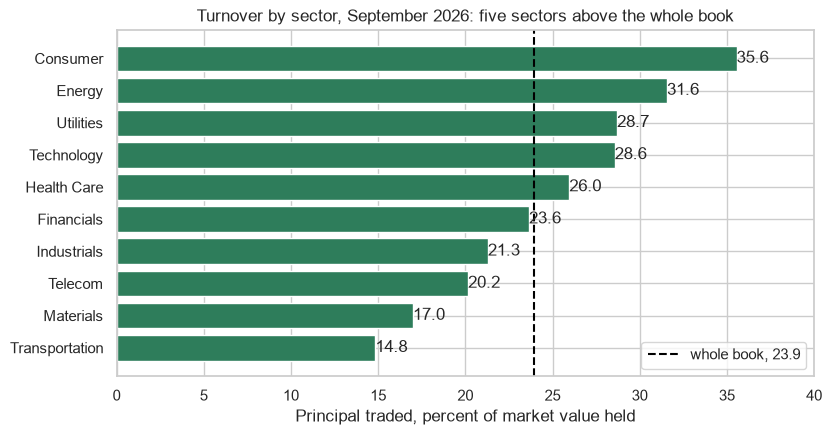

In [29]:
ordered = turnover['turnover_pct'].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(ordered.index, ordered.values)
ax.bar_label(bars, fmt='%.1f')
ax.axvline(whole_pct, color='black', linestyle='--', label='whole book, 23.9')
ax.legend()
ax.set_xlim(0, 40)
ax.set_title('Turnover by sector, September 2026: five sectors above the whole book')
ax.set_xlabel('Principal traded, percent of market value held')
plt.show()

### The Most Traded Bond

Q. Which bond traded most often?

In [30]:
trades_per_bond = trades['cusip'].value_counts()
print(trades_per_bond.head(3).to_dict())
print('traded once:', (trades_per_bond == 1).sum(),
      '| five times or more:', (trades_per_bond >= 5).sum())
top_bond = trades[trades['cusip'] == trades_per_bond.index[0]]
top_bond[['ticker', 'issuer', 'sector', 'rating']].iloc[0]

{'99075XAE9': 20, '99114KAB6': 16, '99007HAA5': 14}
traded once: 57 | five times or more: 25


ticker                CORA
issuer    Corvundra Brands
sector            Consumer
rating                  BB
Name: 16, dtype: str

`99075XAE9`, Corvundra Brands (CORA), a BB Consumer bond, traded 20 times; 57 bonds traded once.

Q. What did CORA trade at, against its month-end price?

In [31]:
simple = top_bond['price'].mean()
# volume-weighted: each price counts by the face traded at it, as Combining Part 2's weighted OAS
weighted = (top_bond['price'] * top_bond['quantity']).sum() / top_bond['quantity'].sum()
month_end = top_bond['month_end_price'].iloc[0]
print('face:', top_bond['quantity'].sum(),
      '| prices:', top_bond['price'].min(), 'to', top_bond['price'].max())
print('simple:', round(simple, 3), '| weighted:', round(weighted, 3), '| month end:', month_end)

face: 3860000 | prices: 99.229 to 100.06
simple: 99.777 | weighted: 99.742 | month end: 99.857


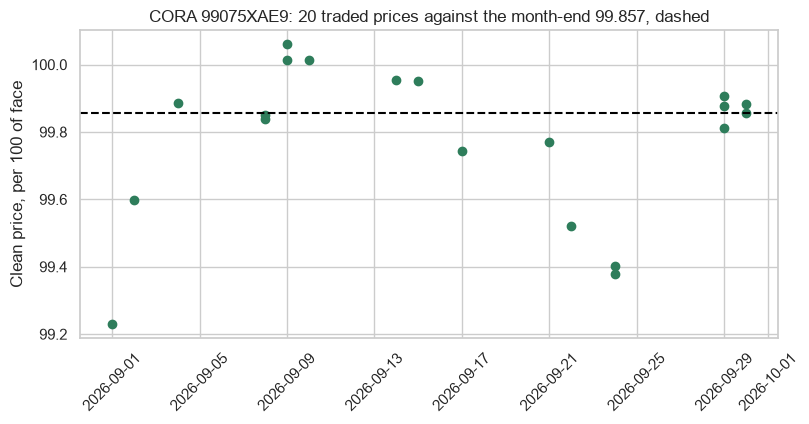

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(top_bond['trade_date'], top_bond['price'])
ax.axhline(month_end, color='black', linestyle='--')
ax.tick_params(axis='x', rotation=45)
ax.set_title('CORA 99075XAE9: 20 traded prices against the month-end 99.857, dashed')
ax.set_ylabel('Clean price, per 100 of face')
plt.show()

The weighted average, 99.742, sits under the simple 99.777: more face traded at the lower prices.
Both sit under the month end, 99.857: say which a page quotes.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Turnover</td><td align="left"><code>traded / held * 100</code></td><td align="left"><code>=SUMIF(O2:O375,"Consumer",J2:J375)/SUMIF(holdings!E2:E201,"Consumer",holdings!S2:S201)*100</code></td><td align="left">35.55</td></tr>
<tr><td align="left">The same trap</td><td align="left"><code>trades['market_value'].sum()</code></td><td align="left"><code>=XLOOKUP(E2,holdings!B:B,holdings!S:S)</code> filled down the blotter, then <code>SUM</code></td><td align="left">1,022,781,137.50 again</td></tr>
<tr><td align="left">Weighted price</td><td align="left"><code>(price * quantity).sum() / quantity.sum()</code></td><td align="left"><code>=SUMPRODUCT((E2:E375="99075XAE9")*I2:I375*H2:H375)/SUMIF(E2:E375,"99075XAE9",H2:H375)</code></td><td align="left">99.742</td></tr>
</table>
<br clear="left">

**23.9 percent of the book changed hands. Last, the month in order.**

## 15.6 Through the Month

### Net by Desk

Q. Bought, sold, and net by desk, in millions?

In [33]:
by_desk = pd.pivot_table(trades, values='principal', index='trader', columns='side',
                         aggfunc='sum') / 1_000_000
by_desk['net'] = by_desk['BUY'] - by_desk['SELL']
print('the nets add to:', round(by_desk['net'].sum(), 2))
by_desk.round(2)

the nets add to: -4.36


side,BUY,SELL,net
trader,,,
Desk 1,9.75,14.71,-4.96
Desk 2,22.86,12.77,10.09
Desk 3,17.04,20.44,-3.40
Desk 4,6.91,13.01,-6.10


Desk 2 net bought 10.09 million; Desks 1, 3, and 4 net sold.
The four nets add to -4.36 again: every cut returns to it.

### Net per Day, Then Running

![The first four dates with their net and running net: 2.98 and 2.98; -0.89 and 2.09; -5.90 and -3.80; 0.70 and -3.11. An arrow carries each running net down to the next row, where the row's net is added. Beside the rows, Excel's SUM with an anchored top cell, filled down](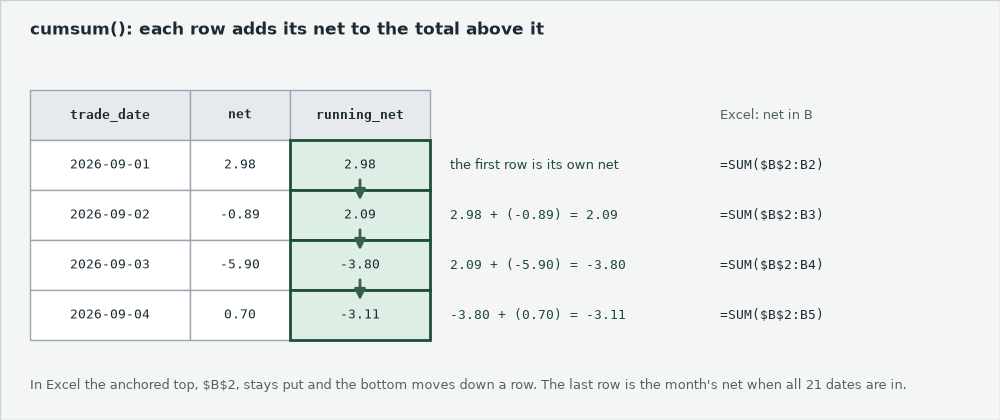)

A **running total** adds each row to every row above it: `cumsum()`, NumPy Part 1's `np.cumsum` on a column.

Q. What was the net each day, and the running net?

In [34]:
# fill_value=0 where a date has no trade on one side, as in Visualization
daily = pd.pivot_table(trades, values='principal', index='trade_date', columns='side',
                       aggfunc='sum', fill_value=0) / 1_000_000
daily['net'] = daily['BUY'] - daily['SELL']
# cumsum() needs the rows in date order; pivot_table sorts its index
daily['running_net'] = daily['net'].cumsum()
print('last running net:', round(daily['running_net'].iloc[-1], 2))
daily.head(4).round(2)

last running net: -4.36


side,BUY,SELL,net,running_net
trade_date,,,,
2026-09-01,5.04,2.06,2.98,2.98
2026-09-02,1.88,2.77,-0.89,2.09
2026-09-03,1.27,7.17,-5.90,-3.80
2026-09-04,2.30,1.60,0.70,-3.11


The first four rows match the picture, and the last row is the total, -4.36: a running total's check.

### Predict 6: The Lowest Point

**Predict 6**

Q. The month ended at -4.36 million. Where was the running net at its lowest?

A) -4.36, at month end
B) between 0 and -4.36
C) below -4.36

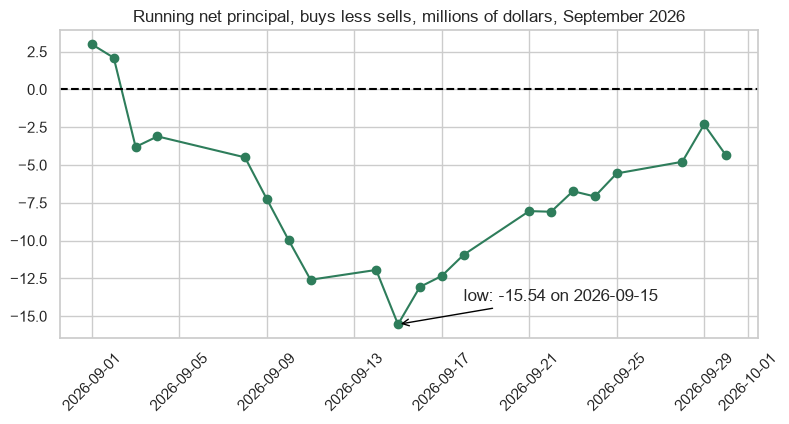

In [35]:
low_day, low = daily['running_net'].idxmin(), daily['running_net'].min()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily.index, daily['running_net'], marker='o')
ax.axhline(0, color='black', linestyle='--')
ax.annotate(f'low: {low:.2f} on {low_day.date()}', xy=(low_day, low),
            xytext=(pd.Timestamp('2026-09-18'), -14),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('Running net principal, buys less sells, millions of dollars, September 2026')
ax.tick_params(axis='x', rotation=45)
plt.show()

C: the low was -15.54 million on 2026-09-15, the day of `T0160`, the 5,000,000 CLAE sale flagged in 15.2.

Q. Which day sold the most net, and where did the running net stand at the end?

In [36]:
print('worst day:', daily['net'].idxmin().date(), round(daily['net'].min(), 2))
print('first below zero:', daily.index[daily['running_net'] < 0][0].date())
print('2026-09-29:', round(daily.loc['2026-09-29', 'running_net'], 2),
      '| 2026-09-30:', round(daily['running_net'].iloc[-1], 2))

worst day: 2026-09-03 -5.9
first below zero: 2026-09-03
2026-09-29: -2.32 | 2026-09-30: -4.36


The running net went below zero on 2026-09-03, the worst day, -5.90, with the RULL sale, and climbed back to -2.32 by 2026-09-29.
One number hides the path.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Signed principal</td><td align="left"><code>BUY</code> less <code>SELL</code></td><td align="left"><code>=IF(G2="BUY",J2,-J2)</code> in Q, filled down</td><td align="left">sells below zero</td></tr>
<tr><td align="left">Running net</td><td align="left"><code>cumsum()</code></td><td align="left"><code>=SUM($Q$2:Q2)</code> in R, filled down: the top stays, the bottom moves</td><td align="left">R375, one row per trade: -4,361,738.45</td></tr>
</table>
<br clear="left">

**-4.36 million at month end, after -15.54 on 2026-09-15: the page's last line.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">File</td><td align="left">374 trades, 12 columns, 2026-09-01 to 2026-09-30; ids unique, no blank, no repeat</td></tr>
<tr><td align="left">Tie-outs</td><td align="left">principal to the cent, round lots, every bond in the book, settle one business day on</td></tr>
<tr><td align="left">Join</td><td align="left">374 in, 374 out; nothing changed, <code>hour</code> and <code>weekday</code> added</td></tr>
</table>
<br clear="left">

## You Can Now

By the end of this notebook, you can:

* Check an unseen file, with an `assert` behind each check.
* Read the hour of a text time with `pd.to_datetime(format=)` and `.dt.hour`.
* Fix the order of text with `pd.Categorical(ordered=True)`.
* Count two columns with `pd.crosstab()`, and box each group with `sns.boxplot()`.
* Tell a count from dollars, and a net from a total.
* Build a running total with `cumsum()` and check its last row.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your code, then run the check cell under it.
First run the next two cells: `check` marks answers; the loader reads fresh tables.

In [37]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [38]:
# fresh copies of the three files, and the lesson's joined table
blotter = pd.read_csv(data_folder + 'trade_blotter.csv', parse_dates=['trade_date', 'settle_date'])
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
bond_details = holdings[['cusip', 'issuer', 'sector', 'rating', 'price', 'market_value']]
bond_details = bond_details.rename(columns={'price': 'month_end_price'})
trades = pd.merge(blotter, bond_details, on='cusip', how='left', validate='many_to_one')
trades = pd.merge(trades, ratings[['rating', 'grade']], on='rating', how='left',
                  validate='many_to_one')
print(blotter.shape, trades.shape)

(374, 12) (374, 18)


### Exercise 1

Q. Apply the IQR rule to `principal`: store the number of trades above the upper limit in **ex1_flagged** and the largest principal in **ex1_largest**. Are they errors?

In [39]:
ex1_flagged = ...
ex1_largest = ...

In [40]:
check('Exercise 1 trades flagged', ex1_flagged, 10)
check('Exercise 1 largest principal', ex1_largest, 5335100.0)

Exercise 1 trades flagged: not attempted yet
Exercise 1 largest principal: not attempted yet


### Exercise 2

Q. Add up the principal by hour, in millions. Store the hour with the most in **ex2_hour** and its principal, to 2 places, in **ex2_millions**. Draw principal by hour as bars.

In [41]:
ex2_hour = ...
ex2_millions = ...

In [42]:
check('Exercise 2 hour', ex2_hour, 11)
check('Exercise 2 millions', ex2_millions, 21.29)

Exercise 2 hour: not attempted yet
Exercise 2 millions: not attempted yet


### Exercise 3

Q. Work out the net principal by grade, in millions to 2 places, in **ex3_ig** and **ex3_hy**; check they add to the blotter's net, and draw them with a zero line.

In [43]:
ex3_ig = ...
ex3_hy = ...

In [44]:
check('Exercise 3 Investment Grade net', ex3_ig, -8.63)
check('Exercise 3 High Yield net', ex3_hy, 4.27)

Exercise 3 Investment Grade net: not attempted yet
Exercise 3 High Yield net: not attempted yet


### Exercise 4

Q. Which bond traded second most often? Store its cusip in **ex4_cusip** and its simple and volume-weighted average prices, to 3 places, in **ex4_simple** and **ex4_weighted**.

In [45]:
ex4_cusip = ...
ex4_simple = ...
ex4_weighted = ...

In [46]:
check('Exercise 4 cusip', ex4_cusip, '99114KAB6')
check('Exercise 4 simple average', ex4_simple, 104.706)
check('Exercise 4 weighted average', ex4_weighted, 104.687)

Exercise 4 cusip: not attempted yet
Exercise 4 simple average: not attempted yet
Exercise 4 weighted average: not attempted yet


### Exercise 5

Q. Complete **weighted_average_price**: given trades and a cusip, return the volume-weighted average traded price to 3 places, and stop with an `assert` and a message when the cusip has no trades.

In [47]:
def weighted_average_price(table, cusip):
    return ...


ex5_first = weighted_average_price(trades, '99075XAE9')
ex5_second = weighted_average_price(trades, '99114KAB6')

In [48]:
if ex5_first is ... or ex5_first is None:
    check('Exercise 5', ex5_first, 99.742)
else:
    check('Exercise 5 99075XAE9', ex5_first, 99.742)
    check('Exercise 5 99114KAB6', ex5_second, 104.687)
    # a cusip with no trades should stop the function; try and except, week 1's Day 3, catch it
    try:
        weighted_average_price(trades, 'NOTACUSIP')
        stopped = False
    except AssertionError as error:
        stopped = True
        print('Stopped with:', error)
    check('Exercise 5 the assert stops a cusip with no trades', stopped, True)

Exercise 5: not attempted yet


### Exercise 6

Q. Group the lesson's `daily` net into weeks ending Friday with `resample('W-FRI')`, as in the Treasury case study. Store the Friday of the most net selling, as text like `'2026-09-04'`, in **ex6_week** and its net in millions, to 2 places, in **ex6_net**. Draw the weekly nets with a zero line.

In [49]:
ex6_week = ...
ex6_net = ...

In [50]:
check('Exercise 6 week', ex6_week, '2026-09-11')
check('Exercise 6 net', ex6_net, -9.48)

Exercise 6 week: not attempted yet
Exercise 6 net: not attempted yet


### Exercise 7: AI check

Q. From the lesson's tables, what should Financials and the whole blotter show? Find the bug and fix the cell.

In [51]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# net dollars bought in each sector, in millions
net_by_sector = trades.groupby('sector')['principal'].sum() / 1_000_000
ex7_financials = round(net_by_sector.loc['Financials'], 2)
ex7_total = round(net_by_sector.sum(), 2)
print('Net bought, Financials:', ex7_financials, '| whole blotter:', ex7_total, 'million dollars')

Net bought, Financials: 16.13 | whole blotter: 117.47 million dollars


In [52]:
check('Exercise 7 Financials net', ex7_financials, -7.04)
check('Exercise 7 whole blotter net', ex7_total, -4.36)

Exercise 7 Financials net: not yet. You have 16.13
Exercise 7 whole blotter net: not yet. You have 117.47


## Congratulations!

You made it through week 3.

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">How much, how big</td><td align="left">374 trades, 117.47 million; median 200,000 of face</td></tr>
<tr><td align="left">Net</td><td align="left">sold 4.36 million net; Financials -7.04, Energy 6.32</td></tr>
<tr><td align="left">Who</td><td align="left">Kestermoor most often, 86 trades; Talvesham most dollars, 36.33 million</td></tr>
<tr><td align="left">Changed hands</td><td align="left">23.9 percent of the book; Consumer 35.55</td></tr>
<tr><td align="left">When</td><td align="left">busiest 09:00 to 11:59; Tuesday 22.40 trades a day</td></tr>
<tr><td align="left">How the net built</td><td align="left">-15.54 on 2026-09-15, -4.36 at month end</td></tr>
</table>
<br clear="left">

Be proud: an unseen file, checked, joined, and cut six ways, every cut tied to -4.36.
Week 4 opens with Case Study: Consumer Credit, the same routine on a new kind of credit data.